<h2 style="break-before: page; page-break-before: always;">
Q3.1
</h2>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import confusion_matrix

SEED = 123123

In [2]:
def split_data(X, y):
    """Split data into train, validation, and test."""

    # 80/20 split: train vs. remaining
    X_train, X_rest, y_train, y_rest = train_test_split(
        X, y, train_size=0.8, random_state=SEED
    )

    # 50/50 split for validation and test
    X_val, X_test, y_val, y_test = train_test_split(
        X_rest, y_rest, train_size=0.5, random_state=SEED
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


def metrics(y_true, y_pred):
    # Positive class is class 1.
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    denom = precision + recall
    f1 = 2 * precision * recall / denom if denom else 0.0
    return {
        "cm": cm,
        "accuracy": (tn + tp) / cm.sum(),
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


def print_metrics(name, m):
    print(f"\n{name}")
    print(m["cm"])
    print(f"  Accuracy: {m['accuracy']:.4f}")
    print(f"  Positive-class precision: {m['precision']:.4f}")
    print(f"  Positive-class recall: {m['recall']:.4f}")
    print(f"  Positive-class F1: {m['f1']:.4f}")

Base classifier validation accuracy: mean 0.9889, min 0.9800, max 0.9940
Base classifier test accuracy: mean 0.9866, min 0.9810, max 0.9920

Bagging ensemble (validation)
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368

Bagging ensemble (test)
[[988   2]
 [  6   4]]
  Accuracy: 0.9920
  Positive-class precision: 0.6667
  Positive-class recall: 0.4000
  Positive-class F1: 0.5000


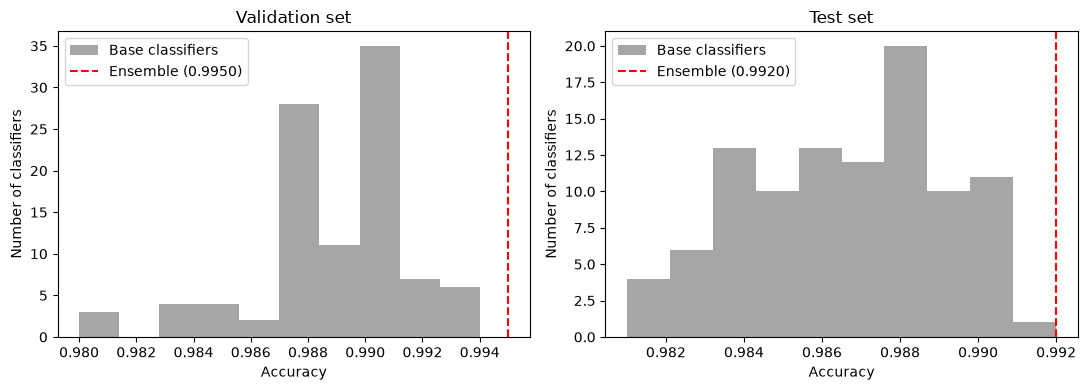

In [3]:
# Load data
data = np.loadtxt('A2Q2-troublesome-data.csv', delimiter=',', skiprows=1)

X = data[:, 1:3]
Y = data[:, 3].astype(int)

# Q3.1 Perform an 80/10/10 split (same split as Q2)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, Y)

# Q3.1 Train 100 trees, each on its own bootstrap sample
# Bootstrap: draw len(X_train) rows with replacement
n_trees = 100
rng = np.random.default_rng(SEED)
trees = []
for _ in range(n_trees):
    rows = rng.integers(0, len(X_train), size=len(X_train))
    tree = DecisionTreeClassifier(random_state=SEED)
    tree.fit(X_train[rows], y_train[rows])
    trees.append(tree)

# Predictions of every tree, shape (n_trees, n_examples)
val_preds = np.array([tree.predict(X_val) for tree in trees])
test_preds = np.array([tree.predict(X_test) for tree in trees])

# Accuracy of each base classifier
base_val_acc = (val_preds == y_val).mean(axis=1)
base_test_acc = (test_preds == y_test).mean(axis=1)

# Majority vote: class 1 if over half vote 1 (tie goes to class 0)
ensemble_val_pred = (val_preds.sum(axis=0) > n_trees / 2).astype(int)
ensemble_test_pred = (test_preds.sum(axis=0) > n_trees / 2).astype(int)
ensemble_val = metrics(y_val, ensemble_val_pred)
ensemble_test = metrics(y_test, ensemble_test_pred)

print(f"Base classifier validation accuracy: mean {base_val_acc.mean():.4f}, "
      f"min {base_val_acc.min():.4f}, max {base_val_acc.max():.4f}")
print(f"Base classifier test accuracy: mean {base_test_acc.mean():.4f}, "
      f"min {base_test_acc.min():.4f}, max {base_test_acc.max():.4f}")
print_metrics("Bagging ensemble (validation)", ensemble_val)
print_metrics("Bagging ensemble (test)", ensemble_test)

# Histogram of base accuracies, ensemble accuracy as a red line
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, set_name, base_acc, ensemble_acc in [
    (axes[0], "Validation", base_val_acc, ensemble_val["accuracy"]),
    (axes[1], "Test", base_test_acc, ensemble_test["accuracy"]),
]:
    ax.hist(base_acc, bins=10, color='gray', alpha=0.7, label='Base classifiers')
    ax.axvline(ensemble_acc, color='red', linestyle='--',
               label=f'Ensemble ({ensemble_acc:.4f})')
    ax.set_xlabel('Accuracy')
    ax.set_ylabel('Number of classifiers')
    ax.set_title(f'{set_name} set')
    ax.legend()
fig.tight_layout()
fig.savefig('q3_1_bagging.png', dpi=150)
plt.show()

<h2 style="break-before: page; page-break-before: always;">
Q3.2
</h2>

In [4]:
# Q3.2 Explore hyperparameter settings for the base decision trees
settings = {
    "max_depth=1": {"max_depth": 1},
    "max_depth=3": {"max_depth": 3},
    "max_depth=5": {"max_depth": 5},
    "default (no limit)": {},
    "min_samples_leaf=5": {"min_samples_leaf": 5},
    "min_samples_leaf=20": {"min_samples_leaf": 20},
}

for label, params in settings.items():
    rng = np.random.default_rng(SEED)
    votes = np.zeros(len(X_val))
    for _ in range(n_trees):
        rows = rng.integers(0, len(X_train), size=len(X_train))
        tree = DecisionTreeClassifier(random_state=SEED, **params)
        tree.fit(X_train[rows], y_train[rows])
        votes += tree.predict(X_val)
    ensemble_pred = (votes > n_trees / 2).astype(int)
    print_metrics(f"Ensemble, {label}", metrics(y_val, ensemble_pred))


Ensemble, max_depth=1
[[984   4]
 [  5   7]]
  Accuracy: 0.9910
  Positive-class precision: 0.6364
  Positive-class recall: 0.5833
  Positive-class F1: 0.6087

Ensemble, max_depth=3
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368

Ensemble, max_depth=5
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368

Ensemble, default (no limit)
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368

Ensemble, min_samples_leaf=5
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368

Ensemble, min_samples_leaf=20
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368


<h2 style="break-before: page; page-break-before: always;">
Q3.6
</h2>

In [5]:
# Q3.6 Three AdaBoost models on the 80% training set (defaults)
ada_models = {
    "AdaBoost (default, estimator=None)": AdaBoostClassifier(random_state=SEED),
    "AdaBoost (Decision Tree)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=SEED), random_state=SEED),
    "AdaBoost (Random Forest)": AdaBoostClassifier(
        estimator=RandomForestClassifier(random_state=SEED), random_state=SEED),
}

for name, model in ada_models.items():
    model.fit(X_train, y_train)
    print_metrics(name, metrics(y_val, model.predict(X_val)))
    print(f"  Base estimators fitted: {len(model.estimators_)}")


AdaBoost (default, estimator=None)
[[985   3]
 [  5   7]]
  Accuracy: 0.9920
  Positive-class precision: 0.7000
  Positive-class recall: 0.5833
  Positive-class F1: 0.6364
  Base estimators fitted: 50

AdaBoost (Decision Tree)
[[981   7]
 [  5   7]]
  Accuracy: 0.9880
  Positive-class precision: 0.5000
  Positive-class recall: 0.5833
  Positive-class F1: 0.5385
  Base estimators fitted: 1

AdaBoost (Random Forest)
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368
  Base estimators fitted: 1


<h2 style="break-before: page; page-break-before: always;">
Q3.8
</h2>

In [6]:
import time
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

# Q3.8 XGBoost vs GradBoost vs AdaBoost (library defaults)
boost_models = {
    "XGBoost": XGBClassifier(random_state=SEED),
    "GradBoost": GradientBoostingClassifier(random_state=SEED),
    "AdaBoost": AdaBoostClassifier(random_state=SEED),
}

for name, model in boost_models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start
    print_metrics(name, metrics(y_val, model.predict(X_val)))
    print(f"  Fit time: {fit_time:.3f} s")


XGBoost
[[985   3]
 [  5   7]]
  Accuracy: 0.9920
  Positive-class precision: 0.7000
  Positive-class recall: 0.5833
  Positive-class F1: 0.6364
  Fit time: 0.038 s

GradBoost
[[986   2]
 [  5   7]]
  Accuracy: 0.9930
  Positive-class precision: 0.7778
  Positive-class recall: 0.5833
  Positive-class F1: 0.6667
  Fit time: 0.445 s

AdaBoost
[[985   3]
 [  5   7]]
  Accuracy: 0.9920
  Positive-class precision: 0.7000
  Positive-class recall: 0.5833
  Positive-class F1: 0.6364
  Fit time: 0.151 s
